# E69: Does RL on Qwen3-1.7B gain more than the same loop with shuffled rewards?

**The answer.** Under the strict grader, reinforcement learning beat the shuffled-reward null on the same test problems on both seeds, by about three and six points. With format set aside, the second seed's lead stays about six however long answers are treated. The first seed's runs from about one point within noise on answers all three states finish, through two and a half on whole answers, to five and a half if an answer past the window counts as wrong, as the reward counts it. That first-seed null ran long more often, and was right more often on answers that finished; we cannot explain why. Our filed lean towards no clear lead reversed on the second seed. That seed's null just cleared its strict band and reads zero with format set aside. RL states the right number six to seven points more often than the unchanged model on GSM8K test, with format set aside, but one shuffled run came close on answers that finish and our graders do not read the working, so we do not claim the reward taught better maths. Two seeds cannot give the lead's size. An independent check reproduced these numbers on 2026-11-04.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_rl")
FIG = ROOT / "figures"
A = json.loads((ROOT / "results/lr1e-6w10/analysis.json").read_text())


def show(name):
    display(Image(filename=str(FIG / name), width=820))


def cell(x):
    return f"{x['mean']:+.1f} ({x['se']:.1f})"


def gains_table(grader):
    head = "| set | arm | drop rule | whole answers | capped answers |\n|---|---|---|---|---|\n"
    names = {"R": "RL", "N": "null", "F": "own-samples SFT", "R-N": "RL minus null"}
    body = ""
    for s, label in (("gsm8k", "GSM8K test"), ("gsm1k", "GSM1K")):
        for a, n in names.items():
            g = A[s]["gains"][grader][a]
            body += f"| {label} | {n} | {cell(g['drop'])} | {cell(g['whole'])} | {cell(g['capped'])} |\n"
    display(Markdown(head + body))


## What we were trying to test

The project needs a real post-training update to carry through a decomposition, and no reinforcement-learning update of Qwen3-1.7B existed. So we trained the unchanged model, with thinking off, on GSM8K train problems for one hundred steps, three ways.

- **RL.** Each step draws 64 new problems and 8 samples per problem at temperature 1. A right answer that ends inside the 512-token window earns reward 1, anything else 0. Each sample's log-probability is pushed by its reward minus its problem's mean reward. This is GRPO in the Dr. GRPO form, with one update per batch.
- **The shuffled-reward null.** The same loop, sampling from its own changing weights, with the rewards shuffled among each problem's samples. It rules out that any update of this size and kind moves accuracy by itself.
- **Own-samples SFT.** Supervised training on the correct samples of the unchanged model, on the same prompts and optimiser. Its samples are drawn once from the unchanged model and never redrawn.

All three use AdamW at a rate of one in a million, reached over ten warm-up steps. Accuracy is the greedy answer, graded strictly. The grader takes the last "The answer is N" anywhere in the response. It is read on GSM8K test, 1,319 problems not trained on. It is also read on GSM1K, 1,197 new problems written in GSM8K's style.

Long answers need a rule, and the code has three. The **drop rule**, which we filed, compares only problems whose answers fit the window both before and after. **Whole answers** grades everything, up to 512 new tokens. **Capped answers** grades everything at the point where the window cuts it. The window is what the reward and the decomposition see.

One seed per arm could not say whether the lead or the null's gain would come back, so a later amendment added three things. **A second seed** of RL and the null, on the same recipe and problems, rules out reading one walk as the arm. **Greedy reads at saved steps** 10, 20 and 50, on GSM8K test, rule out reading step 100 as the end of a steady climb. **Forced openings** on the first seed test whether the opening words carry the null's gain. A **format-relaxed grader** accepts "the answer is N" in either case wherever it stands, with `\boxed` and bold wrappers directly after it, so the lead can be read without the answer line's exact form. It misses display forms such as "the answer is:" followed by a `\boxed` on its own line, so a lenient grader sits beside it at saved steps.


## What we expected, and why

We expected RL to gain three to eight points on test. We expected about the same on GSM1K, since the gain should be skill rather than memory. We expected the null to stay within a point and a half, because its expected gradient is zero. One update per batch also removes the clipping that the Spurious Rewards paper blames for gains under random rewards. We expected a right-over-wrong signal to grow in RL and stay near zero in the null. We did not know whether SFT would move the policy more than RL.

For the second seed we filed that RL's strict lead would replicate, at two points and two standard errors. Under the format-relaxed grader we leaned towards an ambiguous reading or no lead, because the first seed read +1.25 there. We expected forcing "We are" on the unchanged model to add nothing.


## Did RL gain more than the null on the same problems?


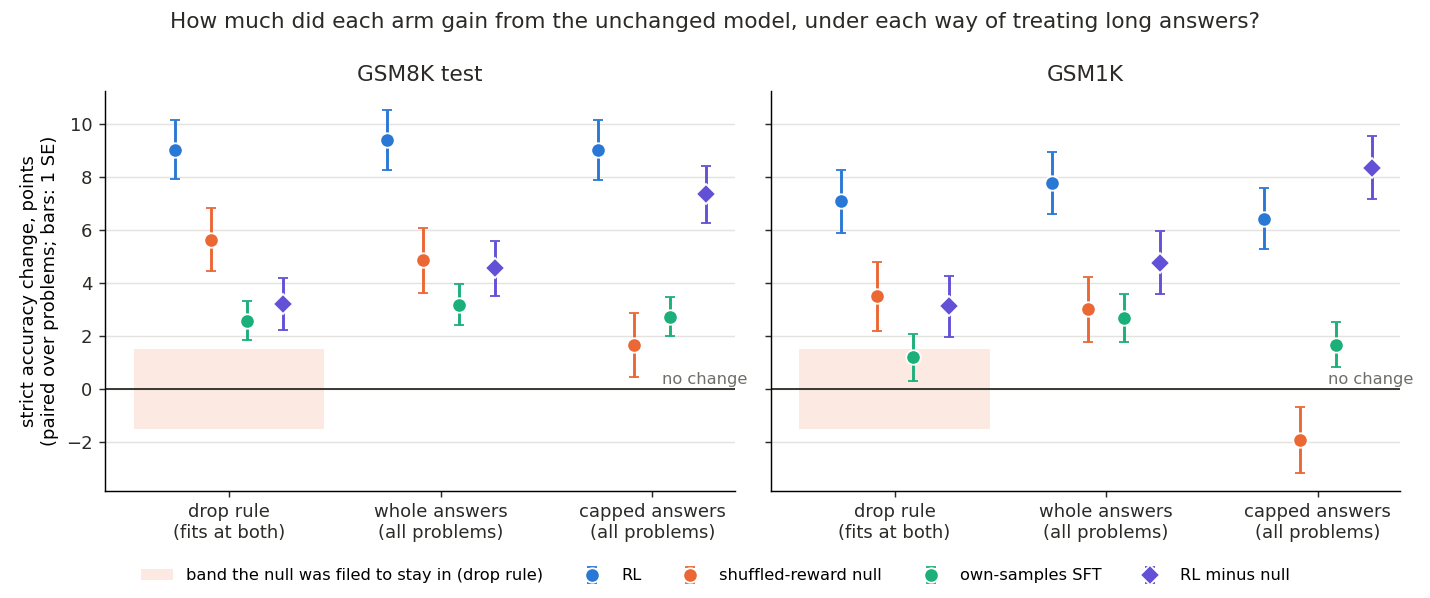

| set | arm | drop rule | whole answers | capped answers |
|---|---|---|---|---|
| GSM8K test | RL | +9.0 (1.1) | +9.4 (1.1) | +9.0 (1.1) |
| GSM8K test | null | +5.6 (1.2) | +4.9 (1.2) | +1.7 (1.2) |
| GSM8K test | own-samples SFT | +2.6 (0.7) | +3.2 (0.8) | +2.7 (0.7) |
| GSM8K test | RL minus null | +3.2 (1.0) | +4.5 (1.0) | +7.4 (1.1) |
| GSM1K | RL | +7.1 (1.2) | +7.8 (1.2) | +6.4 (1.2) |
| GSM1K | null | +3.5 (1.3) | +3.0 (1.2) | -1.9 (1.2) |
| GSM1K | own-samples SFT | +1.2 (0.9) | +2.7 (0.9) | +1.7 (0.8) |
| GSM1K | RL minus null | +3.1 (1.2) | +4.8 (1.2) | +8.4 (1.2) |


In [2]:
show("gains.png")
gains_table("strict")


**Reading it.** Yes under the strict grader, for all three rules and on both sets, and the lead depends on the rule. The violet diamonds are RL minus the null on the same problems. They read about three points under the drop rule, under five on whole answers, and seven or eight on capped answers. RL itself barely depends on the rule, while the null falls from a clear gain to nothing as long answers count against it. These standard errors count problems at fixed weights. They carry no spread between runs of either arm. The two test sets read the same two sets of weights, so their agreement does not replicate the difference between the arms. This figure and the next read the first seed; the second seed follows them.


## Does RL's lead survive a grader that ignores the format?


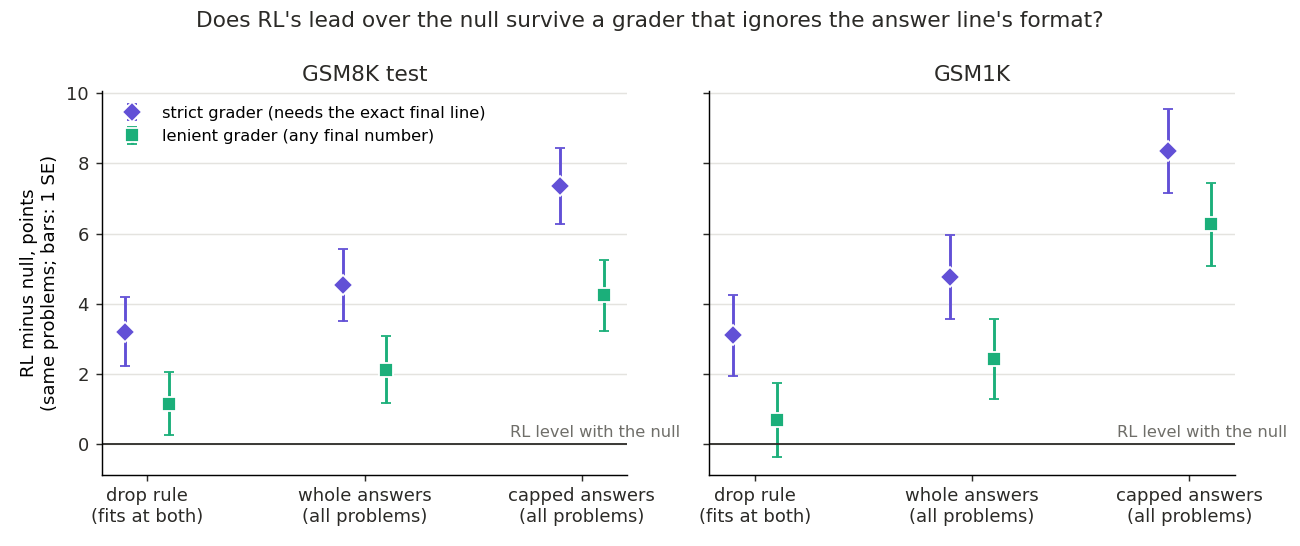

| set | arm | drop rule | whole answers | capped answers |
|---|---|---|---|---|
| GSM8K test | RL | +6.7 (1.1) | +6.3 (1.1) | +6.8 (1.1) |
| GSM8K test | null | +5.4 (1.1) | +4.2 (1.1) | +2.6 (1.1) |
| GSM8K test | own-samples SFT | +0.6 (0.6) | +0.5 (0.6) | +0.5 (0.6) |
| GSM8K test | RL minus null | +1.2 (0.9) | +2.1 (1.0) | +4.2 (1.0) |
| GSM1K | RL | +5.6 (1.1) | +6.0 (1.1) | +5.7 (1.1) |
| GSM1K | null | +4.6 (1.2) | +3.6 (1.1) | -0.6 (1.2) |
| GSM1K | own-samples SFT | +0.0 (0.8) | +0.8 (0.9) | +0.4 (0.8) |
| GSM1K | RL minus null | +0.7 (1.1) | +2.4 (1.1) | +6.3 (1.2) |


In [3]:
show("grader.png")
gains_table("lenient")


**Reading it.** On this first seed, only in part. The lenient grader accepts any final number, so it removes what RL gained by writing the requested answer line. No answer of RL's that fits the window is right yet missing that line. On answers all three states finish, RL's lead falls to about one point, within its error on both sets. With answers allowed to run long it is about two. It reads four to six on capped answers, where an answer past the window counts as wrong, and most of that is the null's answers not finishing. A narrower change says the same. Keeping the strict grader but accepting forms like "So the answer is 20", the lead on answers all three states finish reads +1.25 and +0.81, which this figure does not plot. So on this seed the firm lead may be largely the reward's format, on answers that finish, and the next section shows the second seed does not share that. Own-samples SFT gained almost nothing under the lenient grader, so its gain is format too.


## Does the lead come back on a second seed?


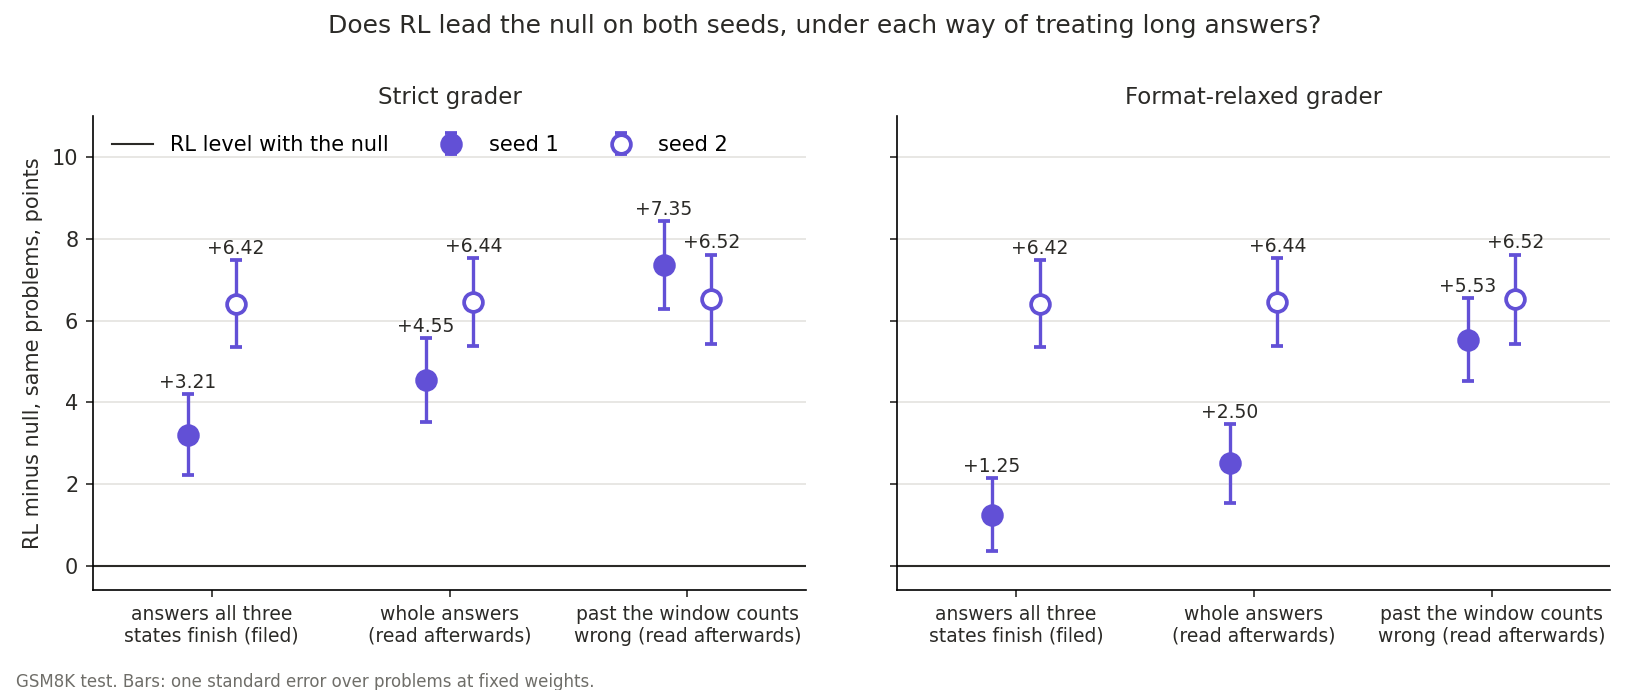

In [4]:
show("leads.png")


**Reading it.** Yes on both seeds, and more than we filed. Each mark is RL minus the null, and the zero line is RL level with the null. The left column of each panel is the filed pool. **Our filed lean, an ambiguous reading or no lead with format set aside, reversed on the second seed**, which reads +6.42 with a standard error of 1.07. The first seed's +1.25 there is 1.4 standard errors from zero, and the same rule would label it ambiguous. The other two columns are unfiled, read after the fact.

The strict and format-relaxed marks coincide on the second seed for a plain reason. The two graders differ on 0 of 1,319 answers per arm there, because every fitting answer holds "The answer is N": 1,255 of 1,255 for RL and 1,277 of 1,277 for the null. The first seed's null wrote it in 1,124 of 1,154, and that gap separates its +3.21 from its +1.25. So "the lead may be largely answer format" is true of the first seed on the filed pool and not of the second seed.

**The gap between seeds depends on the pool.** Format-relaxed, it is about five points on the filed pool, about four on whole answers, and about one if an answer past the window counts as wrong, where the seeds cannot be told apart. As an accounting, the first seed's null fitted fewer answers, 1,154 against 1,277, and was right on more of them, 89.0% against 79.4%. We name no cause. RL's own gains stay within a point of each other. The null's filed strict gain on the second seed is +1.62 with a standard error of 1.11, against a band of 1.5, so it counts as systematic only just, and it reads +0.16 format-relaxed. Better maths is not shown, because these graders read a stated number and not the working.


## Does accuracy climb steadily across saved steps?


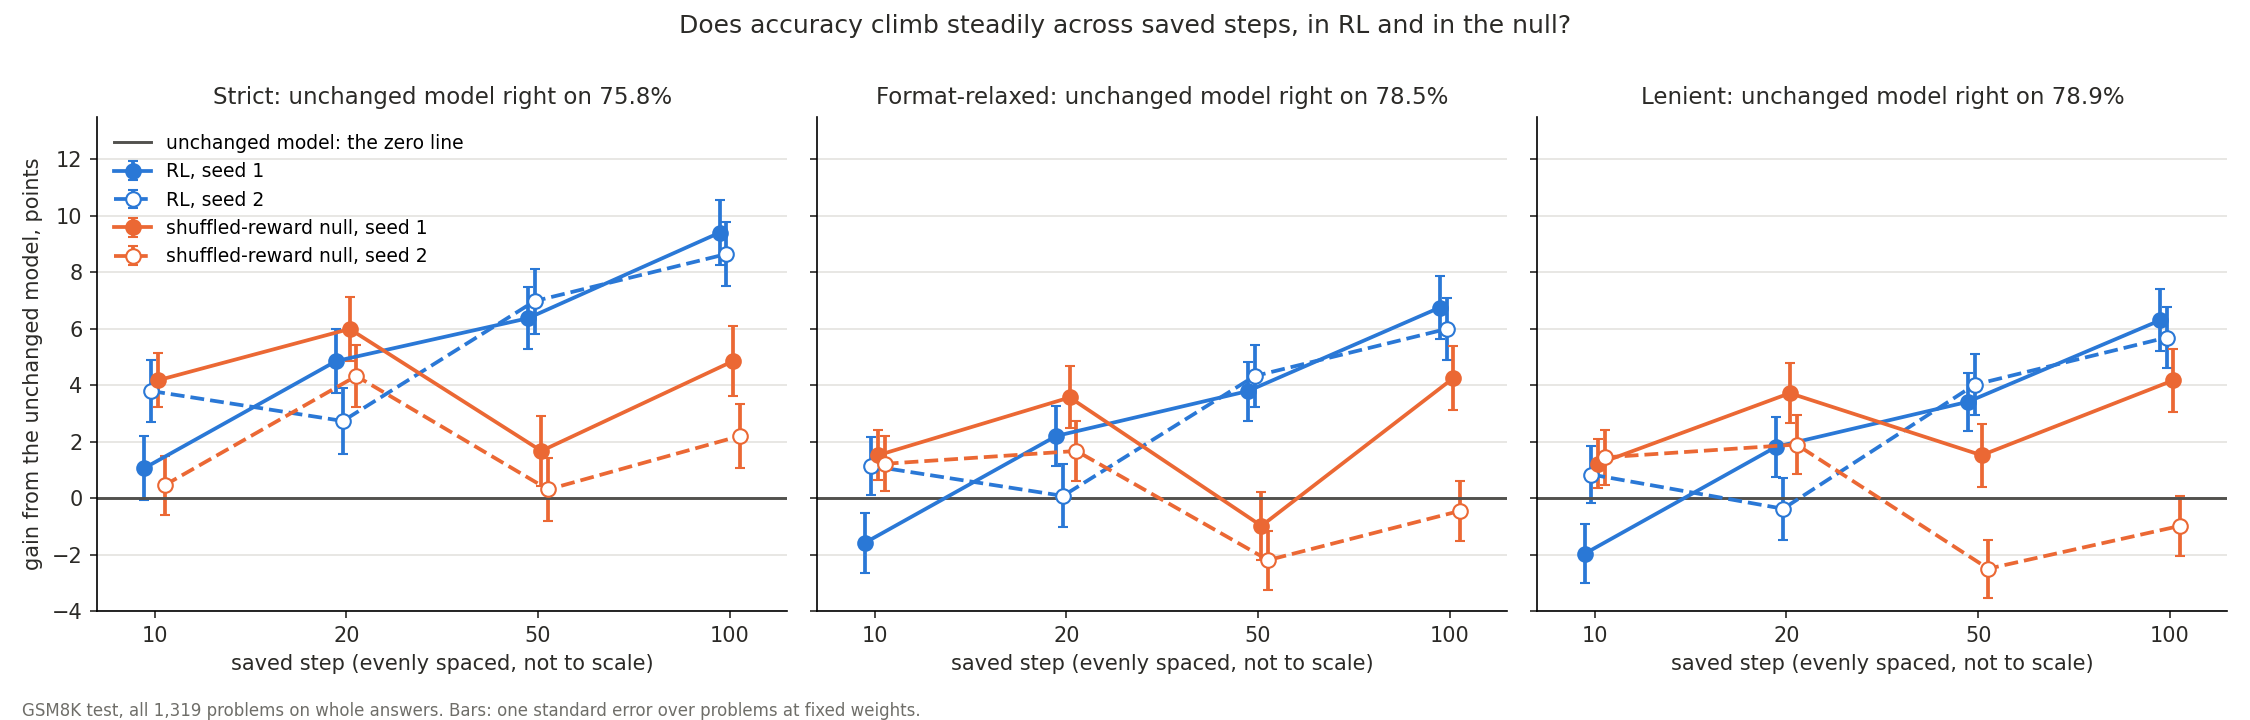

In [5]:
show("saved_steps.png")


**Reading it.** Not in the null, so do not read any single step as a trend. The zero line is the unchanged model. RL rises across the steps on both seeds under all three graders, with one dip on the second seed. Under the strict grader the null moves up and down by about four points between saved steps on both seeds, so its step-100 reading is one point of a walk. Read the lenient panel beside the format-relaxed one here, because the format-relaxed grader misses some display forms at saved steps. The first seed's null at step 50 reads −0.99 format-relaxed and +1.52 lenient, with 39 answers right on one and wrong on the other. At step 100 the two differ on at most one fitting answer, so no filed number moves.

Our filed rule read the null's strict gain at step 50. At least 2.4 points would mean it had arrived by then, along with the switch to "We" openings; under one point would mean it came later. The first seed reads +1.67, which is no call, and the second reads +0.30, which the rule labels "after step 50". We do not explain that difference. RL's lenient gain at step 10 on the first seed read −1.97, missing our expectation of within a point of zero.


## Does the sampled policy agree with greedy accuracy?


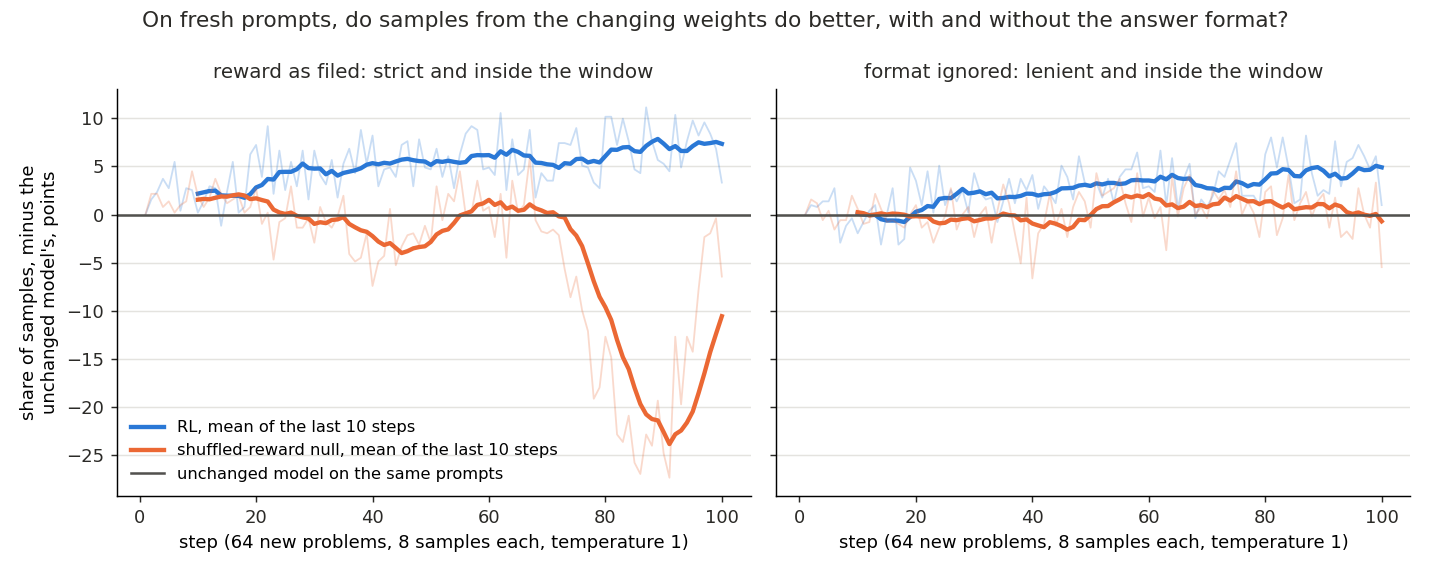

In [6]:
show("reward.png")


**Reading it.** On the first seed, which this figure shows, RL does and the null does not. The zero line is the unchanged model's reward on the same prompts and seeds. On the left, RL climbs to about seven points above it, while the null drifts, then collapses by about twenty points between steps 76 and 95, and largely recovers. On the right, format is ignored and an answer past the window counts as wrong. RL climbs to five points, with a standard error of about one, and the null stays within two points of zero throughout. RL's lead over the null reads +5 in the last five steps and +3 averaged over the last fifty. Among finished samples the null's right-number share rises as much as RL's, and its lower finishing share cancels that. That right panel is the steadiest evidence we have, since the same one hundred steps give the null's noise floor directly. The second seed's decoded samples agree: with format ignored, RL's lead over the null reads +4.53 with a standard error of 1.87 in the last five steps and +4.52 with 0.42 over the last fifty, and that null shows no collapse. No cause is named.


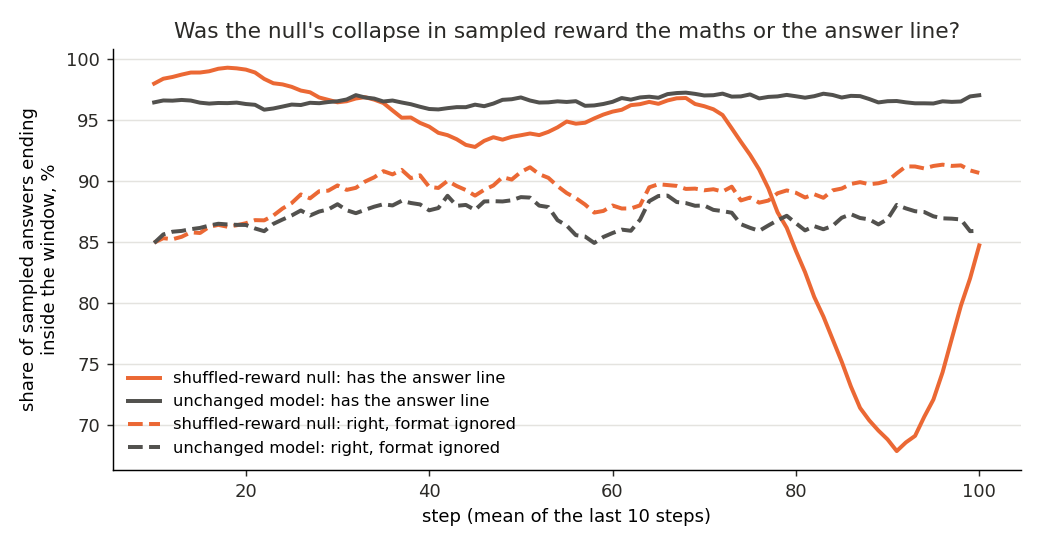

In [7]:
show("collapse.png")


**Reading it.** The first seed's null collapse is the answer line, not the maths, and the second seed's reward shows no such collapse. Solid lines show the share of finished samples that write the requested answer line: the null's drops from about 96 to under 70 percent and comes back. Dashed lines show the share of finished samples right under the lenient grader, and the null's stays at or above the unchanged model's. Finished answers are selected, and the null finishes fewer, so this does not show its maths improved.


## What is the null's gain made of?


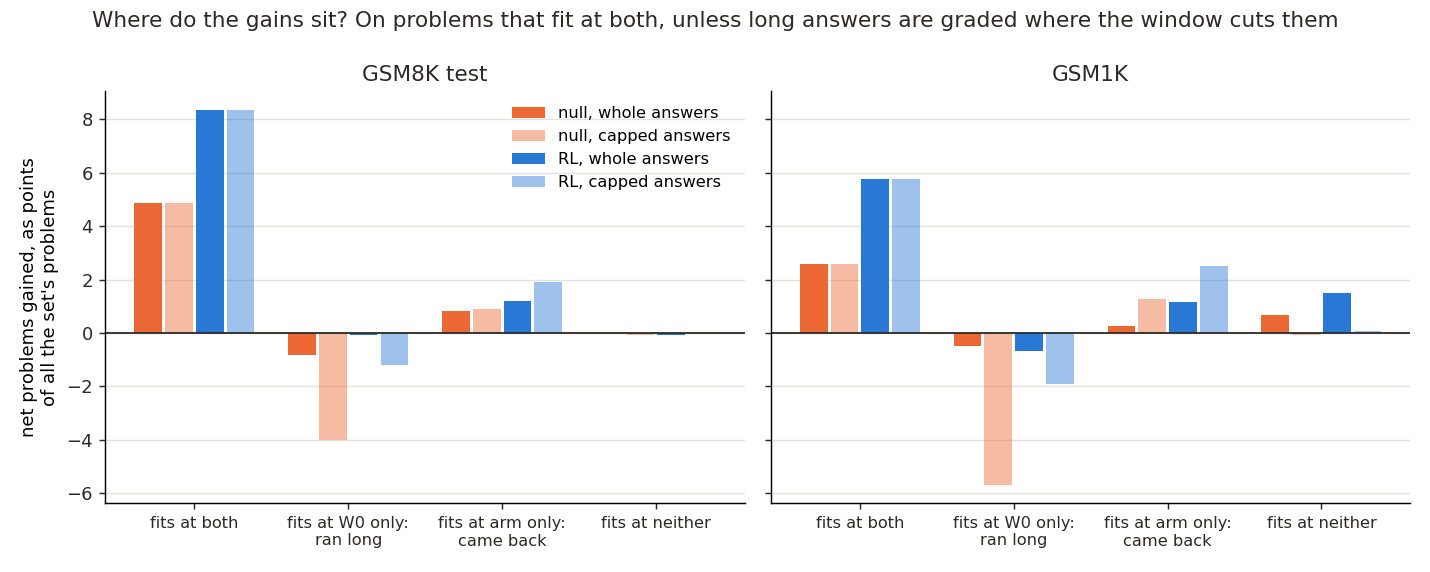

In [8]:
show("accounting.png")


**Reading it.** On the first seed, the filed gain is answers that changed on problems kept at both states. On GSM8K test, 125 kept problems went from wrong to right and 61 from right to wrong, a net of 64. On whole answers the rest nets to zero, so that gain is the same 64 problems. With an answer past the window counted as wrong it nearly vanishes, because 53 problems the unchanged model got right now run past the cut. Twenty-three of those 53 are right if allowed to finish. So the drop rule reads a gain that the window takes back, and on GSM1K the null ends below zero.


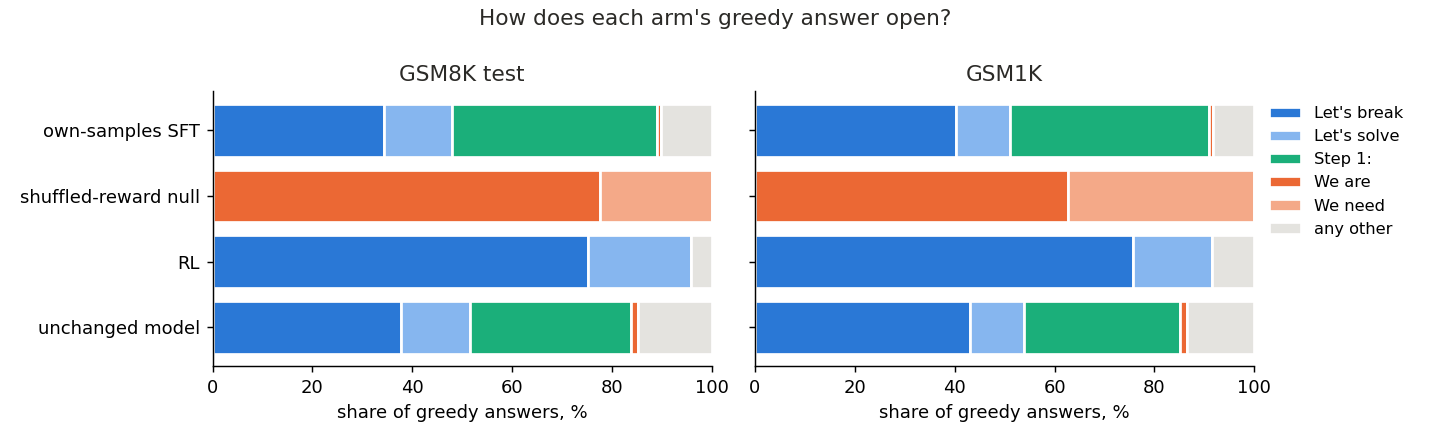

In [9]:
show("openings.png")


**Reading it.** On the first seed every greedy answer of the null opens "We are" or "We need", against under two percent at the unchanged model. RL moved differently, dropping "Step 1:" for "Let's". On the second seed the words differ: every greedy answer of the null on GSM8K test opens "Step 1:", and RL's answers have no common opening.

Forcing the opening was tested on the first seed, and the two filed tests point opposite ways. Prefilling the unchanged model with "We are" changed its strict accuracy by −0.83 points, with a standard error of 1.17, so by that rule the opening does not carry the null's gain. Prefilling the null with the unchanged model's own openings cost it 5.84 points, with a standard error of 1.12, so by that rule it does. Under the format-relaxed grader the same removal costs 1.67. We leave this standing and name no cause of the null's gain.


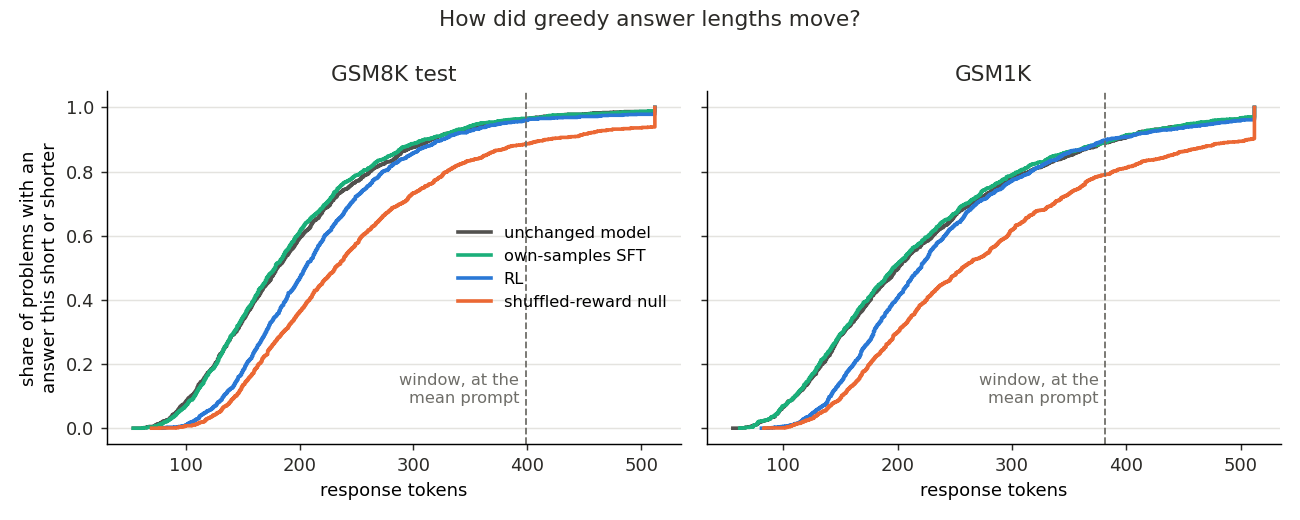

In [10]:
show("lengths.png")


**Reading it.** On the first seed, the null's greedy answers grew by about a quarter, RL's by about a tenth, and SFT's not at all. The null's growth is what pushes problems past the window. Length does not explain the gain problem by problem. Among kept problems, those that went wrong to right lengthened as much as those that went right to wrong. That test is blind to a uniform change of style. Answers with an explicit self-check became far more common in the null, but they do not carry the gain either.


## Does the policy move as the weights move?


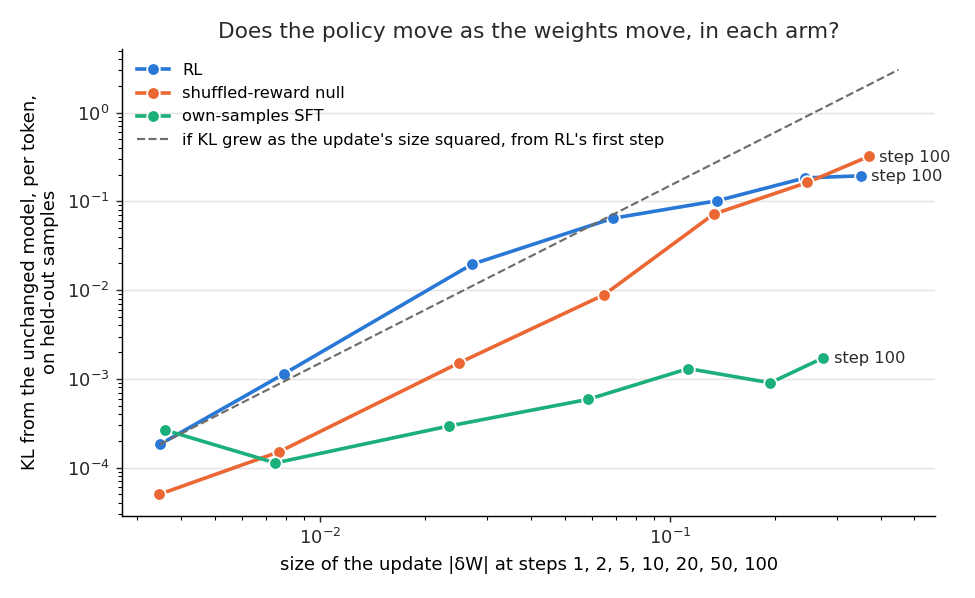

In [11]:
show("kl.png")


**Reading it.** In the null it does, and in own-samples SFT it hardly does. The null runs parallel to the dashed slope, so its divergence from the unchanged model stays proportional to the update's size squared. SFT starts near that line, then falls about a thousandfold below it, and twice its divergence fell while its weights moved further. The update's size at step 100 is still three quarters of the null's. This is what a pull toward the unchanged model would look like, since SFT's samples never leave it. It does not prove that. SFT's weights keep their direction as the others' do, so any such pull acts on the output and not on the weights as a whole. SFT also has no baseline, and RL flattens too. Only an arm that changes one of those things can separate them.


## Does the right-over-wrong signal separate RL from the null?


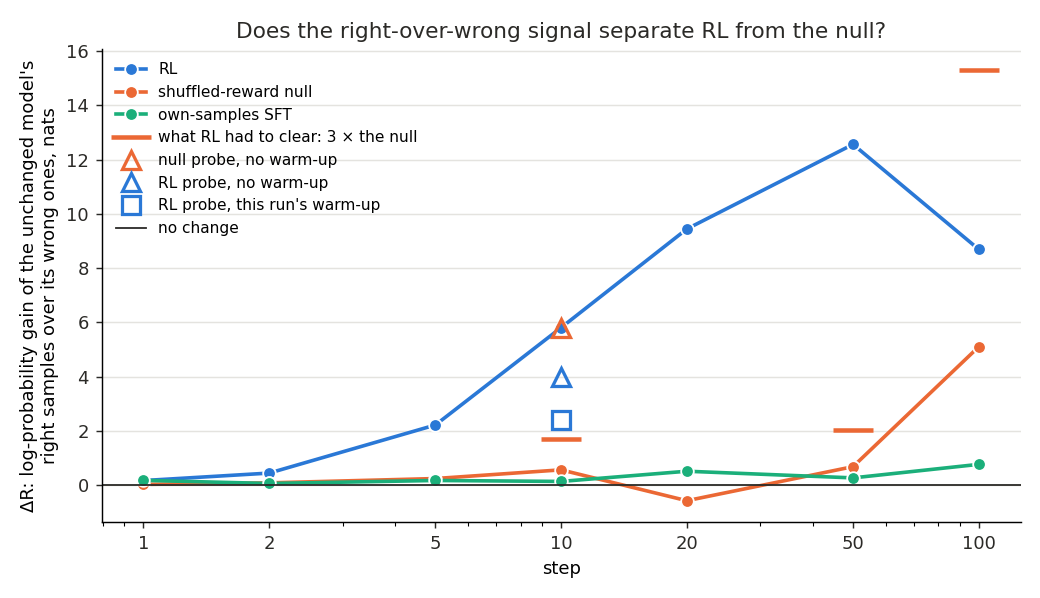

In [12]:
show("delta_r.png")


**Reading it.** Up to step 50 yes, at step 100 no. This signal measures how much more the update favours the unchanged model's right samples over its wrong ones on held-out problems. RL leads by a wide margin until step 50, then drops as the null jumps, so the filed threefold margin fails at the last step. The null's own readings wander around zero and then jump, so this signal has a noise floor of several nats that we did not expect. The orange triangle is the earlier probe of the null without warm-up, about ten times this run's reading at step 10. That probe's path and readout problems both differ, and its standard error was not saved, so the gap is only partly explained.


## What we learned

Under the strict grader, RL's update raised greedy accuracy on fresh problems more than a shuffled-reward run did on both seeds. How much of that lead is the reward's format depends on the seed. On the first seed, on answers all three states finish, format may be most of it and about one point remains within noise; if an answer past the window counts as wrong, five and a half remain. On the second seed none of the lead is format, and six points remain on every pool. Better maths is not shown on either: a shuffled-reward run gained nearly as much with format set aside on the first seed, and the graders do not check the working. The gap between seeds depends on the pool and is unexplained. The update is still ready to go forward to the decomposition, with that reading attached. The null cannot be read as an update that changes no behaviour, since on both seeds it rewrites how nearly every greedy answer opens. The updates' weight changes are almost orthogonal on the first seed, and direction alone does not tell them apart.

## How compelling is the evidence

There are two seeds for RL and the null and one for SFT. Standard errors are over problems and hold the weights fixed, so they say nothing of the spread between seeds, and two seeds size that spread from two points only. The null moves about four points between saved steps, so step 100 is one point on a moving curve. Sampled readings are on training-pool problems, with standard errors over steps, and only the first seed's are decoded. The lenient grader takes the last number and the format-relaxed grader the stated number, so both are coarse stand-ins for correct maths. Accuracy is blind to anything between the saved states. The rule for a replicating lead reads one seed at a time, and the rule on the null's gain carries no standard error. Each forced-opening test changes one state on one seed. An independent check ran on 2026-11-04. It reproduced every number and label and found no leakage, mix-up or bug in the headline, and it did not recheck the δW hashes. In the scorecard, "learns" is the filed label for a gain that met its rule; it does not say what the gain consists of.

## Surprises

**Something unexpected happened that I cannot explain.** We filed a lean that the format-relaxed lead would come back ambiguous or absent on the second seed, and it read +6.42 with a standard error of 1.07, the same as the strict lead. The two seeds differ by about five points there and about one if an answer past the window counts as wrong, and we cannot say why.

We also predicted the shuffled-reward null would stay within a point and a half. On the first seed it gained 5.6 points on GSM8K test under the drop rule, and on the second 1.6. The paper that motivated this design found no gain without clipping, on another model. On the first seed, when an answer past the window counts as wrong, most of the gain cancels, and the whole-answer gain does not. We cannot say why.

Four more. SFT's divergence from the unchanged model is about a hundred times smaller than RL's, the opposite of the filed direction. The first seed's sampled reward in the null collapsed and recovered late in the run, by losing the answer line. On each seed, every greedy answer of the null moved to a small set of openings, and those openings differ between seeds. The two forced-opening tests read opposite ways.

## What next

1. Hash the second seed's δW files before the decomposition reads them, at no cost, since the independent check did not. A mismatch would stop any reading of them.
2. A decision on a third seed, about $20. It adds a lead on each way of treating long answers, and which seed then looks odd depends on that treatment. We recommend reading the two seeds first.


In [13]:
rows = [
    ("P0", "the unchanged model's accuracy near the baseline", "within 1.5 points of 77.7 and 78.2", "78.2 and 78.9; both readings zero at step 0; 52 readout problems", "holds"),
    ("P1", "RL learns on GSM8K test", "gain at least 2 points and 2 SE", "+9.0 (1.1)", "learns"),
    ("P2", "the gain is not memory", "GSM1K minus GSM8K under 2 points and within 2 SE", "-2.0 (1.6)", "same"),
    ("P3", "the null gains nothing", "|gain| under 1.5 points", "+5.6 (1.2)", "**miss**"),
    ("P4", "early signal separates RL from the null", "positive at every step; at least 3x the null's at 10, 50, 100", "positive; 10.3x, 18.5x; 1.7x at step 100", "**miss** at 100"),
    ("P6", "lengths stay put", "steps 91-100 within 25% of steps 1-10; 90% inside the window", "1.13x; 96.3%", "holds"),
    ("P7", "SFT moves the policy more; gains no more than RL", "KL at least 3x RL's; gain at most RL's", "0.0017 against 0.194; +2.6 against +9.0", "**miss**, first part opposite"),
    ("G0", "control: the relaxed grader reproduces the first seed", "+1.25 (0.90), +0.81 (1.06) as printed", "as printed", "holds"),
    ("S0", "control: the second seed's RL learns", "as P1", "+8.3 (1.1)", "learns"),
    ("S1", "RL's lead on the second seed, strict", "at least 2 points and 2 SE; under 1 none", "+6.42 (1.07)", "replicates"),
    ("S1r", "the same, format-relaxed; lean ambiguous or none", "as S1", "+6.42 (1.07)", "replicates; **lean reversed**"),
    ("S2", "the null's gain on the second seed", "|gain| at least 1.5, first seed's sign", "+1.62 (1.11)", "systematic, only just"),
    ("B1", "the null's gain has arrived by step 50", "at least 2.4 arrives; under 1 after", "+1.67; +0.30", "no call; after step 50"),
    ("E_R10", "RL's lenient gain at step 10, first seed", "within 1 point of zero", "-1.97", "**missed**"),
    ("A1", "\"We are\" on the unchanged model carries the gain", "at least 2.4 carries; at most 0 not", "-0.83", "not, as expected"),
    ("A2", "the null without its opening loses the gain", "loses at least 2.425: carries", "loses 5.84", "carries"),
]
head = "| id | claim | rule | read | verdict |\n|---|---|---|---|---|\n"
display(Markdown("## Scorecard\n\nP5 was withdrawn before filing. Rows from G0 on are the amendment's, on the rules in `predictions_amend1.json`; each is a filed label, not a claim about maths.\n\n" + head + "".join("| " + " | ".join(r) + " |\n" for r in rows)))


## Scorecard

P5 was withdrawn before filing. Rows from G0 on are the amendment's, on the rules in `predictions_amend1.json`; each is a filed label, not a claim about maths.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| P0 | the unchanged model's accuracy near the baseline | within 1.5 points of 77.7 and 78.2 | 78.2 and 78.9; both readings zero at step 0; 52 readout problems | holds |
| P1 | RL learns on GSM8K test | gain at least 2 points and 2 SE | +9.0 (1.1) | learns |
| P2 | the gain is not memory | GSM1K minus GSM8K under 2 points and within 2 SE | -2.0 (1.6) | same |
| P3 | the null gains nothing | |gain| under 1.5 points | +5.6 (1.2) | **miss** |
| P4 | early signal separates RL from the null | positive at every step; at least 3x the null's at 10, 50, 100 | positive; 10.3x, 18.5x; 1.7x at step 100 | **miss** at 100 |
| P6 | lengths stay put | steps 91-100 within 25% of steps 1-10; 90% inside the window | 1.13x; 96.3% | holds |
| P7 | SFT moves the policy more; gains no more than RL | KL at least 3x RL's; gain at most RL's | 0.0017 against 0.194; +2.6 against +9.0 | **miss**, first part opposite |
| G0 | control: the relaxed grader reproduces the first seed | +1.25 (0.90), +0.81 (1.06) as printed | as printed | holds |
| S0 | control: the second seed's RL learns | as P1 | +8.3 (1.1) | learns |
| S1 | RL's lead on the second seed, strict | at least 2 points and 2 SE; under 1 none | +6.42 (1.07) | replicates |
| S1r | the same, format-relaxed; lean ambiguous or none | as S1 | +6.42 (1.07) | replicates; **lean reversed** |
| S2 | the null's gain on the second seed | |gain| at least 1.5, first seed's sign | +1.62 (1.11) | systematic, only just |
| B1 | the null's gain has arrived by step 50 | at least 2.4 arrives; under 1 after | +1.67; +0.30 | no call; after step 50 |
| E_R10 | RL's lenient gain at step 10, first seed | within 1 point of zero | -1.97 | **missed** |
| A1 | "We are" on the unchanged model carries the gain | at least 2.4 carries; at most 0 not | -0.83 | not, as expected |
| A2 | the null without its opening loses the gain | loses at least 2.425: carries | loses 5.84 | carries |


## Not run

- A third seed of RL and the null, or a second seed of SFT.
- A recheck of the δW hashes by the independent check.
- Greedy accuracy at steps 1, 2 and 5, or on GSM1K at any saved step.
- Forced openings on the second seed.
- An arm that varies one difference between SFT and the null: fixed samples or no baseline.
- A standard error on the right-over-wrong signal, at any step of this run.
- Autocast rollouts, as real post-training runs use. This run is full precision throughout.
- Any map or any read of the decomposition, which belongs to the next stage.

## Provenance

Results under `experiments/qwen_rl/results/lr1e-6w10/` and `lr1e-6w10_s70/`, per-problem files under `results/large/`, numbers in `analysis.json` from `experiments/qwen_rl/plot.py`, `amend1_score.json` from `score_amend1.py` and `amend1_reading.json` from `plot_amend1.py`. First seed: one H100, about $33. Second seed: one H100, 3.9 h for its two arms, plus cluster L40 reads at no cost. Report: `reports/analyses/2026-11-03_analysis_e69-grpo-loop.md`, with every table and the departures from the literature.
